In [29]:
import pandas as pd

study = pd.concat([
    pd.read_csv("nm-study.csv"),
    pd.read_csv("nm-study-m.csv"),
    pd.read_csv("nm-study-n.csv"),
    pd.read_csv("nm-study-p.csv"),
    pd.read_csv("nm-study-4.csv"),
    pd.read_csv("nm-study-5.csv"),
])

print(study.shape)
study["label"].value_counts()

(12489, 64)


,count
label,
P,2566
M,1966
N,1604
V,382
X,347
I,320
E,315
G,308
D,306


In [30]:
study.head()

,label,x0,y0,z0,x1,y1,z1,x2,y2,z2,...,z17,x18,y18,z18,x19,y19,z19,x20,y20,z20
0,A,0.733144,0.573169,-4.365725e-07,0.687322,0.533162,-0.016027,0.672607,0.437198,-0.018703,...,-0.007667,0.796698,0.388961,-0.021204,0.784179,0.438006,-0.012528,0.777522,0.457315,-0.001928
1,A,0.732674,0.574128,-4.319262e-07,0.687126,0.533448,-0.016031,0.672505,0.437023,-0.018846,...,-0.008275,0.796247,0.388995,-0.021712,0.783876,0.437429,-0.012931,0.777443,0.457151,-0.002260
2,A,0.733037,0.574241,-4.315717e-07,0.687245,0.532966,-0.015742,0.672638,0.437676,-0.018459,...,-0.007561,0.795836,0.388865,-0.021151,0.783589,0.437119,-0.012504,0.776594,0.457011,-0.001839
3,A,0.732760,0.573794,-4.346418e-07,0.686875,0.533607,-0.015908,0.672448,0.437142,-0.018592,...,-0.008451,0.795664,0.388836,-0.022022,0.783211,0.437138,-0.013348,0.776481,0.456631,-0.002754
4,A,0.732757,0.573624,-4.373545e-07,0.686866,0.534187,-0.016033,0.672454,0.437330,-0.018727,...,-0.008588,0.795301,0.388703,-0.022217,0.782817,0.437641,-0.013524,0.776233,0.456958,-0.002906


In [31]:
old = pd.read_csv("nm-study.csv")
old = old[~old["label"].isin(["J", "Z", "N", "P"])]   # drop moving letters + the bad N and P

study = pd.concat([
    old,                                  # session 1 (cleaned)
    pd.read_csv("nm-study-m.csv"),        # M redo
    pd.read_csv("nm-study-n.csv"),        # N redo
    pd.read_csv("nm-study-p.csv"),        # P redo
    pd.read_csv("nm-study-2.csv"),        # session 2: close up
    pd.read_csv("nm-study-3.csv"),        # session 3: far away, left hand
    pd.read_csv("nm-study-4.csv"),        # session 4
    pd.read_csv("nm-study-5.csv"),        # session 5
])

print(study["label"].nunique(), "letters")
study["label"].value_counts()

24 letters


,count
label,
P,2860
M,2343
N,1709
Q,713
R,627
V,607
X,605
T,598
Y,597


In [32]:
study = study.sample(frac=1, random_state=42)
study = study.groupby("label").head(150)

print(study.shape)

(3600, 64)


In [33]:
import numpy as np

KEY_DOTS = [0, 4, 8, 12, 16, 20, 5, 9, 13, 17]   # wrist, 5 fingertips, 4 knuckles

def normalise(row):
    hand = row.reshape(21, 3)          # 63 numbers → 21 dots, each with x, y, z
    hand = hand - hand[0]              # slide the hand so the wrist sits at 0,0,0
    palm = np.linalg.norm(hand[9])     # palm size = distance from wrist to dot 9
    hand = hand / palm                 # measure everything in palms

    a, b = hand[5], hand[17]           # is this the "other" hand?
    if a[0] * b[1] - a[1] * b[0] < 0:
        hand[:, 0] = -hand[:, 0]       # if so, mirror it

    # NEW: extra clues, the distance between every pair of key dots
    distances = []
    for i in range(len(KEY_DOTS)):
        for j in range(i + 1, len(KEY_DOTS)):
            distances.append(np.linalg.norm(hand[KEY_DOTS[i]] - hand[KEY_DOTS[j]]))

    return np.concatenate([hand.flatten(), distances])   # 63 positions + 45 distances = 108 numbers

numbers = study.drop(columns="label").to_numpy()
X = np.array([normalise(row) for row in numbers])

print(X.shape)

(3600, 108)


In [34]:
letters = sorted(study["label"].unique())
y = np.array([letters.index(letter) for letter in study["label"]])

print(letters)
print(y[:10])

['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y']
[14 21 15 14  0 14 12 13 15 23]


In [35]:
import tensorflow as tf
tf.keras.utils.set_random_seed(42)

model = tf.keras.Sequential([
    tf.keras.Input(shape=(X.shape[1],)),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(len(letters), activation="softmax"),
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 128)            │        13,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 24)             │         1,560 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,768 (92.84 KB)

 Trainable params: 23,768 (92.84 KB)

 Non-trainable params: 0 (0.00 B)

In [36]:
history = model.fit(X, y, epochs=30, batch_size=32)

Epoch 1/30
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4133 - loss: 2.1216
Epoch 2/30
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7908 - loss: 0.7540
Epoch 3/30
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8642 - loss: 0.4400
Epoch 4/30
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9064 - loss: 0.3124
Epoch 5/30
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9192 - loss: 0.2529
Epoch 6/30
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9369 - loss: 0.2012
Epoch 7/30
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9478 - loss: 0.1656
Epoch 8/30
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9647 - loss: 0.1337
Epoch 9/30
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9681 - loss: 0.1201
Epoch 10/30
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9722 - loss: 0.1021
Epoch 11/30
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9819 - loss: 0.0842
Epoch 12/30
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

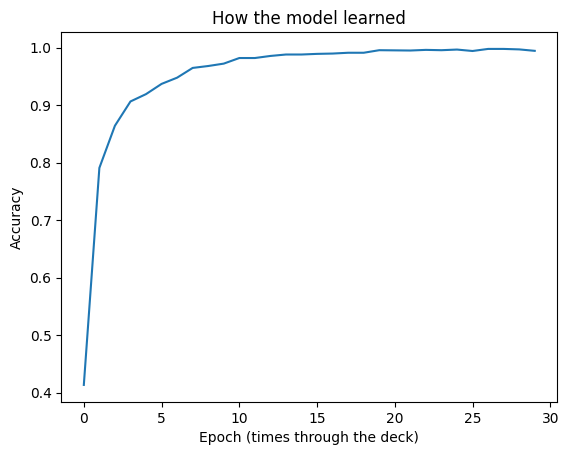

In [37]:
import matplotlib.pyplot as plt

plt.plot(history.history["accuracy"])
plt.xlabel("Epoch (times through the deck)")
plt.ylabel("Accuracy")
plt.title("How the model learned")
plt.show()

In [38]:
guesses = model.predict(X[:5])

for i in range(5):
    print("Real answer:", letters[y[i]], "| Model says:", letters[guesses[i].argmax()], f"({guesses[i].max():.0%} sure)")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
Real answer: P | Model says: P (100% sure)
Real answer: W | Model says: W (100% sure)
Real answer: Q | Model says: Q (100% sure)
Real answer: P | Model says: P (100% sure)
Real answer: A | Model says: A (100% sure)


In [39]:
exam = pd.read_csv("nm-exam.csv")
exam = exam[~exam["label"].isin(["J", "Z"])]

X_exam = np.array([normalise(row) for row in exam.drop(columns="label").to_numpy()])
y_exam = np.array([letters.index(letter) for letter in exam["label"]])

print(X_exam.shape)

(2853, 108)


In [40]:
loss, accuracy = model.evaluate(X_exam, y_exam)
print(f"Exam score: {accuracy:.0%}")

90/90 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9271 - loss: 0.1433
Exam score: 93%


In [41]:
guesses = model.predict(X_exam).argmax(axis=1)

results = pd.DataFrame({
    "real": [letters[i] for i in y_exam],
    "guess": [letters[i] for i in guesses],
})
results["correct"] = results["real"] == results["guess"]

results.groupby("real")["correct"].mean().round(2)

90/90 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


,correct
real,
A,1.00
B,1.00
C,1.00
D,1.00
E,0.01
F,1.00
G,1.00
H,1.00
I,1.00


In [42]:
pd.crosstab(results["real"], results["guess"])

guess,A,B,C,D,E,F,G,H,I,K,...,P,Q,R,S,T,U,V,W,X,Y
real,,,,,,,,,,,,,,,,,,,,,
A,120,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
B,0,87,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
C,0,0,111,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
D,0,0,0,125,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
E,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
F,0,0,0,0,0,89,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
G,0,0,0,0,0,0,121,0,0,0,...,0,0,0,0,0,0,0,0,0,0
H,0,0,0,0,0,0,0,107,0,0,...,0,0,0,0,0,0,0,0,0,0
I,0,0,0,0,0,0,0,0,105,0,...,0,0,0,0,0,0,0,0,0,0


In [43]:
one_at_a_time = tf.keras.Sequential([
    tf.keras.Input(shape=(X.shape[1],), batch_size=1),   # exactly 1 card at a time
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(len(letters), activation="softmax"),
])
one_at_a_time.set_weights(model.get_weights())          # copy the trained dials across

converter = tf.lite.TFLiteConverter.from_keras_model(one_at_a_time)
tflite_model = converter.convert()

with open("letters.tflite", "wb") as f:
    f.write(tflite_model)

print(f"Model file: {len(tflite_model) / 1024:.0f} KB")

Saved artifact at '/tmp/tmpsoy6nr4_'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(1, 108), dtype=tf.float32, name='keras_tensor_20')
Output Type:
  TensorSpec(shape=(1, 24), dtype=tf.float32, name=None)
Captures:
  136120740310544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136120740310736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136120762946896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136120762953040: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136120762955344: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136120762954576: TensorSpec(shape=(), dtype=tf.resource, name=None)
Model file: 95 KB


In [44]:
import json

cards = exam.drop(columns="label").to_numpy()[[0, 2300]]   # card 0 = A (left hand), card 2300 = Q (right hand)

fixture = [{"raw": card.tolist(), "features": normalise(card).tolist()} for card in cards]

with open("letter-features.fixture.json", "w") as f:
    json.dump(fixture, f)

print(exam["label"].iloc[0], exam["label"].iloc[2300])

A Q


In [45]:
interpreter = tf.lite.Interpreter(model_path="letters.tflite")
interpreter.allocate_tensors()
input_slot = interpreter.get_input_details()[0]["index"]
output_slot = interpreter.get_output_details()[0]["index"]

expected = model.predict(X_exam[:100], verbose=0).argmax(axis=1)

same = 0
for i in range(100):
    interpreter.set_tensor(input_slot, X_exam[i:i+1].astype(np.float32))
    interpreter.invoke()
    if interpreter.get_tensor(output_slot).argmax() == expected[i]:
        same += 1

print(f"Packed model agrees with the original on {same}/100 exam cards")

Packed model agrees with the original on 100/100 exam cards


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [46]:
import json

with open("letters.json", "w") as f:
    json.dump(letters, f)

print(letters)

['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y']
